# Laboratorio Computacional: Compresión Extrema a 1-Bit (SignSGD) vs. SGD Tradicional en Enlaces Inalámbricos

**IE-0629 Sistemas de Comunicación — Escuela de Ingeniería Eléctrica, Universidad de Costa Rica (UCR)**

---

## 1. Introducción teórica y motivación en telecomunicaciones

### Objetivos del laboratorio
1. Implementar **desde cero** el SGD distribuido tradicional (gradientes en float32) y **SignSGD con votación mayoritaria** (1 bit por parámetro).
2. Comparar empíricamente precisión, estabilidad y **tráfico de subida (uplink)**.
3. Estudiar la robustez de SignSGD ante errores de bit en un **canal binario simétrico (BSC)**.

### El cuello de botella de subida (*uplink bottleneck*)
En aprendizaje distribuido sobre redes inalámbricas, $M$ dispositivos entrenan un modelo con parámetros $\theta \in \mathbb{R}^d$ y, en cada ronda, envían su gradiente al servidor. El enlace de subida suele ser el recurso más escaso (potencia limitada del dispositivo, ancho de banda compartido).

- **SGD estándar:** cada dispositivo transmite $32 \times d$ bits por ronda (float32).
- **SignSGD:** cada dispositivo transmite solo $\text{sign}(g_i) \in \{-1,+1\}$, es decir $1 \times d$ bits por ronda.

$$\text{Factor de reducción} = \frac{32\,d}{d} = 32\times \qquad\Longrightarrow\qquad \text{ahorro} = 1 - \frac{1}{32} = 96.875\,\%$$

### Mecánica de SignSGD distribuido (votación mayoritaria)
Cada cliente $m \in \{1,\dots,M\}$ calcula su gradiente local $\mathbf{g}_m$ y transmite $\text{sign}(\mathbf{g}_m)$. El servidor agrega por coordenada:

$$\mathbf{v} = \text{sign}\left(\sum_{m=1}^{M} \text{sign}(\mathbf{g}_m)\right)$$

y actualiza el modelo global con un paso de **magnitud fija** $\gamma$:

$$\theta_{t+1} = \theta_t - \gamma\,\mathbf{v}$$

> **Nota:** usamos $M$ **impar** para evitar empates en la votación. Además, como un bit solo representa dos valores, la convención es $\text{sign}(0) := +1$ al transmitir.

## 0. Configuración del entorno
Solo se usan `torch`, `torchvision`, `numpy` y `matplotlib`. Fijamos semillas para que las gráficas sean **reproducibles en el aula**.

In [1]:
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets
import matplotlib.pyplot as plt

SEED = 23

def fijar_semilla(seed=SEED):
    """Fija las semillas de PyTorch y NumPy para reproducibilidad."""
    torch.manual_seed(seed)
    np.random.seed(seed)

fijar_semilla()
torch.set_num_threads(max(1, torch.get_num_threads()))  # usa los hilos de CPU disponibles
print(f"PyTorch {torch.__version__} | CPU suficiente, no se requiere GPU")

# Estilo sobrio de ingeniería para las gráficas
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.grid": True,
    "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "legend.frameon": False,
})

PyTorch 2.15.0+cu132 | CPU suficiente, no se requiere GPU


## 2. Carga y preparación del dataset (MNIST)
- Cargamos MNIST con `torchvision.datasets` (requiere conexión a internet la primera vez).
- **Submuestreo controlado:** 14 000 imágenes de entrenamiento y 2 000 de prueba, para correr en pocos minutos en CPU o Google Colab.
- **Entorno distribuido:** $M = 7$ clientes (impar), cada uno con un fragmento IID de 2 000 muestras.

In [2]:
N_TRAIN = 14_000      # muestras de entrenamiento (submuestreo)
N_TEST  = 2_000       # muestras de prueba
M       = 7           # número de clientes (IMPAR para evitar empates en la votación)

train_set = datasets.MNIST("./data", train=True,  download=True)
test_set  = datasets.MNIST("./data", train=False, download=True)

def a_tensores(ds, n, gen):
    """Toma n imágenes al azar, las normaliza y las aplana a vectores de 784."""
    idx = torch.randperm(len(ds), generator=gen)[:n]
    X = ds.data[idx].float().div(255.0)
    X = (X - 0.1307) / 0.3081                 # media y desviación estándar de MNIST
    return X.view(n, -1), ds.targets[idx]

gen_datos = torch.Generator().manual_seed(SEED)
X_train, y_train = a_tensores(train_set, N_TRAIN, gen_datos)
X_test,  y_test  = a_tensores(test_set,  N_TEST,  gen_datos)

# Partición IID del entrenamiento entre los M clientes
perm = torch.randperm(N_TRAIN, generator=gen_datos)
fragmentos = torch.chunk(perm, M)
clientes = [(X_train[idx], y_train[idx]) for idx in fragmentos]

print(f"Entrenamiento: {X_train.shape} | Prueba: {X_test.shape}")
print(f"Clientes: {M} | muestras por cliente: {[len(c[1]) for c in clientes]}")

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.48MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 380kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.30MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.71MB/s]


Entrenamiento: torch.Size([14000, 784]) | Prueba: torch.Size([2000, 784])
Clientes: 7 | muestras por cliente: [2000, 2000, 2000, 2000, 2000, 2000, 2000]


## 3. Definición del modelo de clasificación
Usamos un **perceptrón multicapa** claro: $784 \to 128 \to 10$ con activación ReLU. Tiene $d = 784\cdot128 + 128 + 128\cdot10 + 10 = 101\,770$ parámetros, es decir $d \approx 10^5$.

In [3]:
class MLP(nn.Module):
    """MLP compacto 784 -> 128 -> 10 para clasificar dígitos MNIST."""
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        return self.fc2(F.relu(self.fc1(x)))


def contar_parametros(model):
    """Número total de parámetros entrenables d."""
    return sum(p.numel() for p in model.parameters())


def resumen_trafico(model, n_clientes):
    """Imprime los megabits por ronda en float32 vs. SignSGD (1 bit)."""
    d = contar_parametros(model)
    mb_32 = 32 * d / 1e6
    mb_1  = 1  * d / 1e6
    print(f"Número total de parámetros d = {d:,}")
    print(f"{'':28s}{'por dispositivo':>18s}{f'total ({n_clientes} disp.)':>20s}")
    print(f"{'SGD float32 (32 bits)':28s}{mb_32:>14.3f} Mb{mb_32*n_clientes:>16.3f} Mb")
    print(f"{'SignSGD (1 bit)':28s}{mb_1:>14.3f} Mb{mb_1*n_clientes:>16.3f} Mb")
    print(f"Factor de reducción: {mb_32/mb_1:.0f}x  |  ahorro: {100*(1-mb_1/mb_32):.3f} %")

resumen_trafico(MLP(), M)

Número total de parámetros d = 101,770
                               por dispositivo     total (7 disp.)
SGD float32 (32 bits)                3.257 Mb          22.796 Mb
SignSGD (1 bit)                      0.102 Mb           0.712 Mb
Factor de reducción: 32x  |  ahorro: 96.875 %


## 4. Implementación manual de los optimizadores
Ningún optimizador de `torch.optim`: el paso de actualización se escribe a mano para ver exactamente **qué se transmite** y **cómo se agrega**.

Convención: `clients_gradients` es una lista de $M$ elementos; cada elemento es la lista de gradientes (un tensor por parámetro del modelo) del cliente $m$.

In [4]:
def gradientes_locales(model, X, y):
    """Cada cliente calcula su gradiente local sobre un minilote (X, y)."""
    model.zero_grad()
    perdida = F.cross_entropy(model(X), y)
    perdida.backward()
    grads = [p.grad.detach().clone() for p in model.parameters()]
    return grads, perdida.item()


# ---------------------------------------------------------------------------
# Función A: SGD distribuido tradicional (gradientes float32, 32 bits/parámetro)
# ---------------------------------------------------------------------------
@torch.no_grad()
def step_distributed_sgd(model, clients_gradients, lr):
    """El servidor recibe M gradientes continuos, los promedia y descuenta."""
    for i, p in enumerate(model.parameters()):
        g_prom = torch.stack([g[i] for g in clients_gradients]).mean(dim=0)  # (1/M) sum g_m
        p.add_(g_prom, alpha=-lr)                                            # theta <- theta - lr * g_prom


# ---------------------------------------------------------------------------
# Utilidades de 1 bit y canal BSC
# ---------------------------------------------------------------------------
def signo_1bit(g):
    """sign(g) en {-1,+1}. Con torch.sign(0)=0 hace falta una convención: sign(0):=+1."""
    s = torch.sign(g)
    return torch.where(s == 0, torch.ones_like(s), s)


def canal_bsc(signos, pe, gen=None):
    """Canal binario simétrico: cada bit de signo se invierte con probabilidad pe."""
    inversiones = torch.rand(signos.shape, generator=gen) < pe
    return torch.where(inversiones, -signos, signos)


# ---------------------------------------------------------------------------
# Función B: SignSGD con votación mayoritaria (1 bit/parámetro)
# ---------------------------------------------------------------------------
@torch.no_grad()
def step_sign_sgd_majority_vote(model, clients_gradients, lr, pe=0.0, gen=None):
    """
    1) Cada cliente transmite sign(g_m)  (1 bit por parámetro).
    2) (Opcional) los bits pasan por un BSC con probabilidad de error pe.
    3) El servidor suma los signos y aplica sign() de nuevo: voto mayoritario.
    4) Paso de magnitud fija: theta <- theta - lr * v
    """
    for i, p in enumerate(model.parameters()):
        signos = torch.stack([signo_1bit(g[i]) for g in clients_gradients])  # (M, *forma)
        if pe > 0:
            signos = canal_bsc(signos, pe, gen)
        voto = torch.sign(signos.sum(dim=0))   # M impar => la suma nunca es 0
        p.add_(voto, alpha=-lr)

## 5. Simulación experimental y comparación de métricas
Entrenamos **el mismo modelo** (misma inicialización, mismos minilotes, `seed = 23`) con ambos métodos. Por cada época registramos:
- **Pérdida de entrenamiento** (promedio de las rondas de la época).
- **Precisión en prueba.**
- **Volumen acumulado transmitido en subida**, sumando los $M$ dispositivos: $M \cdot d \cdot b$ bits por ronda, con $b = 32$ ó $b = 1$.

> **Tasa de aprendizaje:** en SGD el paso es $\text{lr}\cdot\bar{g}$ (proporcional a la magnitud del gradiente), mientras que en SignSGD **cada parámetro se mueve exactamente $\gamma$** por ronda. Por eso $\gamma$ es mucho menor que `lr` (ver pregunta 2).

In [5]:
@torch.no_grad()
def precision_prueba(model):
    """Precisión (%) sobre el conjunto de prueba."""
    pred = model(X_test).argmax(dim=1)
    return 100.0 * (pred == y_test).float().mean().item()


def entrenar(metodo, epocas=15, lr=0.1, batch=32, pe=0.0, seed=SEED, verbose=True):
    """
    metodo: "sgd" (float32) o "sign" (SignSGD con voto mayoritario).
    pe:     probabilidad de error de bit del BSC (solo aplica a "sign").
    Devuelve un diccionario con el historial por época.
    """
    fijar_semilla(seed)
    model = MLP()                                         # misma inicialización en ambos métodos
    gen_lotes = torch.Generator().manual_seed(seed)       # mismo orden de minilotes
    gen_canal = torch.Generator().manual_seed(seed + 1)   # ruido del canal reproducible

    d = contar_parametros(model)
    bits_por_param = 32 if metodo == "sgd" else 1
    n_local = len(clientes[0][0])
    rondas_por_epoca = n_local // batch

    hist = {"loss": [], "acc": [], "mbits": []}
    mbits_acum = 0.0

    for ep in range(1, epocas + 1):
        perms = [torch.randperm(n_local, generator=gen_lotes) for _ in range(M)]
        perdida_ep = 0.0
        for r in range(rondas_por_epoca):
            grads, perdidas = [], []
            for m, (Xm, ym) in enumerate(clientes):
                idx = perms[m][r * batch:(r + 1) * batch]
                g, l = gradientes_locales(model, Xm[idx], ym[idx])
                grads.append(g)
                perdidas.append(l)

            if metodo == "sgd":
                step_distributed_sgd(model, grads, lr)
            else:
                step_sign_sgd_majority_vote(model, grads, lr, pe=pe, gen=gen_canal)

            mbits_acum += M * d * bits_por_param / 1e6   # bits de subida de los M dispositivos
            perdida_ep += float(np.mean(perdidas))

        hist["loss"].append(perdida_ep / rondas_por_epoca)
        hist["acc"].append(precision_prueba(model))
        hist["mbits"].append(mbits_acum)
        if verbose:
            print(f"[{metodo:4s}] época {ep:2d} | pérdida {hist['loss'][-1]:.4f} | "
                  f"acc {hist['acc'][-1]:5.2f} % | subida acumulada {mbits_acum:10.1f} Mb")
    return hist

### 5.1 (Opcional) Barrido rápido de $\gamma$ para SignSGD
Como el paso de SignSGD es de magnitud fija, **$\gamma$ es el hiperparámetro crítico**: muy grande oscila, muy pequeño no avanza. Este barrido corto (4 épocas) ayuda a escoger un valor razonable. Si cambia el mejor valor, actualice `LR_SIGN` en la siguiente celda.

In [6]:
for g in [0.0005, 0.001, 0.002, 0.005]:
    h = entrenar("sign", epocas=4, lr=g, verbose=False)
    print(f"gamma = {g:<7} -> precisión tras 4 épocas: {h['acc'][-1]:5.2f} %")

/home_nfs/Rodrigo/anaconda3/envs/6.86x/lib/python3.11/site-packages/torch/autograd/graph.py:1113: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12050). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


gamma = 0.0005  -> precisión tras 4 épocas: 92.45 %
gamma = 0.001   -> precisión tras 4 épocas: 93.15 %
gamma = 0.002   -> precisión tras 4 épocas: 92.90 %
gamma = 0.005   -> precisión tras 4 épocas: 92.75 %


In [7]:
EPOCAS   = 15
LR_SGD   = 0.1      # SGD tradicional
LR_SIGN  = 0.002    # SignSGD (magnitud de paso fija gamma); ajustar con el barrido 5.1

hist_sgd  = entrenar("sgd",  epocas=EPOCAS, lr=LR_SGD)
print()
hist_sign = entrenar("sign", epocas=EPOCAS, lr=LR_SIGN)

[sgd ] época  1 | pérdida 0.7420 | acc 89.80 % | subida acumulada     1413.4 Mb
[sgd ] época  2 | pérdida 0.3351 | acc 92.00 % | subida acumulada     2826.8 Mb
[sgd ] época  3 | pérdida 0.2807 | acc 92.80 % | subida acumulada     4240.1 Mb
[sgd ] época  4 | pérdida 0.2426 | acc 93.50 % | subida acumulada     5653.5 Mb
[sgd ] época  5 | pérdida 0.2168 | acc 93.30 % | subida acumulada     7066.9 Mb
[sgd ] época  6 | pérdida 0.1922 | acc 93.90 % | subida acumulada     8480.3 Mb
[sgd ] época  7 | pérdida 0.1748 | acc 94.15 % | subida acumulada     9893.7 Mb
[sgd ] época  8 | pérdida 0.1592 | acc 94.55 % | subida acumulada    11307.1 Mb
[sgd ] época  9 | pérdida 0.1445 | acc 94.45 % | subida acumulada    12720.4 Mb
[sgd ] época 10 | pérdida 0.1326 | acc 94.30 % | subida acumulada    14133.8 Mb
[sgd ] época 11 | pérdida 0.1225 | acc 94.55 % | subida acumulada    15547.2 Mb
[sgd ] época 12 | pérdida 0.1139 | acc 95.25 % | subida acumulada    16960.6 Mb
[sgd ] época 13 | pérdida 0.1049 | acc 9

## 6. Visualización gráfica
Dos subgráficas: **(a)** precisión vs. épocas, **(b)** precisión vs. megabits transmitidos en subida (eje horizontal logarítmico, porque las magnitudes difieren en más de un orden de magnitud).

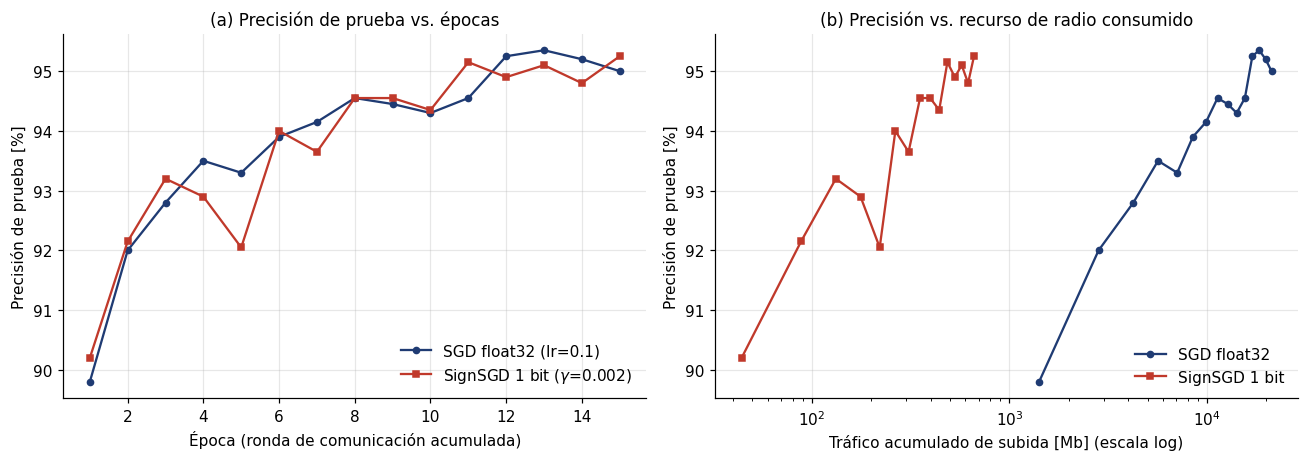

Método              Acc final [%]   Subida total [Mb]      [MB]
SGD float32                 95.00             21200.7    2650.1
SignSGD 1 bit               95.25               662.5      82.8

Reducción de tráfico: 32x
Diferencia de precisión (SGD - SignSGD): -0.25 puntos porcentuales


In [8]:
epocas = np.arange(1, EPOCAS + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))

# (a) Precisión vs. épocas
ax[0].plot(epocas, hist_sgd["acc"],  "o-", ms=4, color="#1f3b73", label=f"SGD float32 (lr={LR_SGD})")
ax[0].plot(epocas, hist_sign["acc"], "s-", ms=4, color="#c0392b", label=f"SignSGD 1 bit ($\\gamma$={LR_SIGN})")
ax[0].set_xlabel("Época (ronda de comunicación acumulada)")
ax[0].set_ylabel("Precisión de prueba [%]")
ax[0].set_title("(a) Precisión de prueba vs. épocas")
ax[0].legend(loc="lower right")

# (b) Precisión vs. megabits transmitidos
ax[1].plot(hist_sgd["mbits"],  hist_sgd["acc"],  "o-", ms=4, color="#1f3b73", label="SGD float32")
ax[1].plot(hist_sign["mbits"], hist_sign["acc"], "s-", ms=4, color="#c0392b", label="SignSGD 1 bit")
ax[1].set_xscale("log")
ax[1].set_xlabel("Tráfico acumulado de subida [Mb] (escala log)")
ax[1].set_ylabel("Precisión de prueba [%]")
ax[1].set_title("(b) Precisión vs. recurso de radio consumido")
ax[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

# Resumen numérico
print(f"{'Método':18s}{'Acc final [%]':>15s}{'Subida total [Mb]':>20s}{'[MB]':>10s}")
for nombre, h in [("SGD float32", hist_sgd), ("SignSGD 1 bit", hist_sign)]:
    print(f"{nombre:18s}{h['acc'][-1]:>15.2f}{h['mbits'][-1]:>20.1f}{h['mbits'][-1]/8:>10.1f}")
print(f"\nReducción de tráfico: {hist_sgd['mbits'][-1]/hist_sign['mbits'][-1]:.0f}x")
print(f"Diferencia de precisión (SGD - SignSGD): {hist_sgd['acc'][-1]-hist_sign['acc'][-1]:.2f} puntos porcentuales")

**Para discutir:** ¿alcanza SignSGD una precisión competitiva? Compare la gráfica (b): ¿cuántos Mb necesita cada método para llegar, por ejemplo, a 90 % de precisión? ¿Qué diferencia observa en la **estabilidad** (suavidad) de las curvas?

### 6.1 Del ahorro de bits al ahorro de recursos de radio (apoyo para la pregunta 1)
Supongamos un enlace de subida de ancho de banda $B$ con eficiencia espectral $\eta$ [bit/s/Hz]. El tiempo de transmisión de $d\,b$ bits es $T = d\,b/(B\eta)$. Si fijamos el **tiempo** disponible, la eficiencia espectral requerida baja $32\times$, y por Shannon ($\eta = \log_2(1+\text{SNR})$) el SNR requerido cae drásticamente. En un canal con desvanecimiento Rayleigh, la probabilidad de *outage* es $P_{out} = 1 - \exp\!\left(-\text{SNR}_{req}/\overline{\text{SNR}}\right)$.

In [9]:
d = contar_parametros(MLP())
B_hz  = 1e6      # ancho de banda del enlace de subida: 1 MHz
eta   = 2.0      # eficiencia espectral base [bit/s/Hz] usada con 32 bits/parámetro
SNR_promedio_dB = 10.0

# (i) Mismo ancho de banda y eficiencia => cuánto dura cada ronda por dispositivo
for nombre, b in [("float32", 32), ("1 bit", 1)]:
    T = d * b / (B_hz * eta)
    print(f"Tiempo de subida por dispositivo ({nombre:7s}): {T*1e3:8.1f} ms")

# (ii) Mismo tiempo de subida => eficiencia espectral y SNR requeridos
for nombre, e in [("float32", eta), ("1 bit", eta / 32)]:
    snr_req = 2**e - 1
    snr_med = 10**(SNR_promedio_dB / 10)
    p_out   = 1 - math.exp(-snr_req / snr_med)       # Rayleigh
    print(f"{nombre:7s}: eta={e:6.4f} b/s/Hz | SNR requerido = {10*np.log10(snr_req):6.2f} dB "
          f"| P_out Rayleigh (SNR medio {SNR_promedio_dB:.0f} dB) = {p_out:.4f}")

Tiempo de subida por dispositivo (float32):   1628.3 ms
Tiempo de subida por dispositivo (1 bit  ):     50.9 ms
float32: eta=2.0000 b/s/Hz | SNR requerido =   4.77 dB | P_out Rayleigh (SNR medio 10 dB) = 0.2592
1 bit  : eta=0.0625 b/s/Hz | SNR requerido = -13.54 dB | P_out Rayleigh (SNR medio 10 dB) = 0.0044


## 7. Simulación opcional: robustez ante ruido de canal (BSC)
Modelamos la transmisión de cada bit de signo como un **canal binario simétrico** con probabilidad de error $P_e$. SignSGD con votación mayoritaria funciona como un **código de repetición espacial**: cada coordenada la "reportan" $M$ dispositivos y el servidor decide por mayoría.

### 7.1 Análisis teórico
Si los $M$ dispositivos enviaran el mismo bit y cada uno se invierte independientemente con probabilidad $P_e$, el error de la mayoría es

$$P_{err}^{(M)} = \sum_{k=(M+1)/2}^{M} \binom{M}{k} P_e^{\,k}(1-P_e)^{M-k}$$

(En SignSGD los signos locales no coinciden perfectamente por el ruido del gradiente, así que esta fórmula es una referencia del **efecto del canal**, no del error total del voto.)

In [10]:
def p_error_mayoria(M, pe):
    """Probabilidad de que la mayoría de M bits (M impar) sea errónea en un BSC(pe)."""
    return sum(math.comb(M, k) * pe**k * (1 - pe)**(M - k) for k in range((M + 1) // 2, M + 1))

pes = [0.01, 0.05, 0.1]
print(f"{'M':>3s} | " + " | ".join(f"Pe={pe:<5}" for pe in pes))
for Mx in [1, 3, 5, 7, 9, 15]:
    print(f"{Mx:>3d} | " + " | ".join(f"{p_error_mayoria(Mx, pe):<8.2e}" for pe in pes))

  M | Pe=0.01  | Pe=0.05  | Pe=0.1  
  1 | 1.00e-02 | 5.00e-02 | 1.00e-01
  3 | 2.98e-04 | 7.25e-03 | 2.80e-02
  5 | 9.85e-06 | 1.16e-03 | 8.56e-03
  7 | 3.42e-07 | 1.94e-04 | 2.73e-03
  9 | 1.22e-08 | 3.32e-05 | 8.91e-04
 15 | 6.05e-13 | 1.83e-07 | 3.36e-05


### 7.2 Simulación
Reentrenamos SignSGD inyectando el BSC sobre los bits de signo de cada cliente, **sin retransmisiones ARQ ni codificación de canal**. Se incluye $P_e = 0$ como referencia.

> SGD en float32 no se compara aquí a propósito: un solo bit invertido en el exponente de un float32 puede producir valores enormes, así que requeriría protección con codificación de canal o ARQ.

Pe = 0.0   -> precisión final: 95.25 %
Pe = 0.01  -> precisión final: 94.65 %
Pe = 0.05  -> precisión final: 94.85 %
Pe = 0.1   -> precisión final: 94.95 %


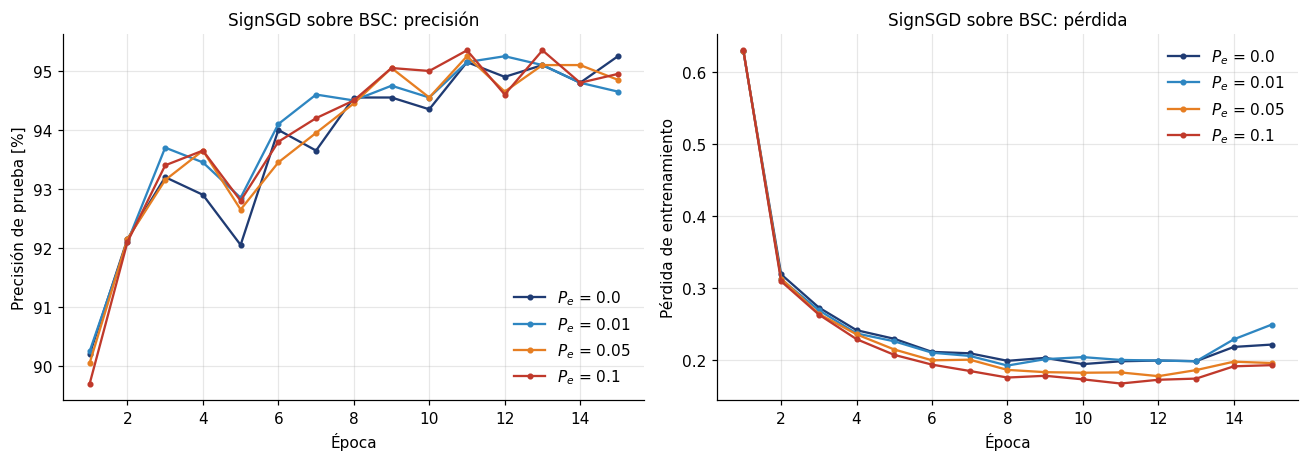

In [11]:
valores_pe = [0.0, 0.01, 0.05, 0.1]
colores = ["#1f3b73", "#2e86c1", "#e67e22", "#c0392b"]
resultados_bsc = {}

for pe in valores_pe:
    resultados_bsc[pe] = entrenar("sign", epocas=EPOCAS, lr=LR_SIGN, pe=pe, verbose=False)
    print(f"Pe = {pe:<5} -> precisión final: {resultados_bsc[pe]['acc'][-1]:5.2f} %")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
for pe, c in zip(valores_pe, colores):
    ax[0].plot(epocas, resultados_bsc[pe]["acc"],  "o-", ms=3, color=c, label=f"$P_e$ = {pe}")
    ax[1].plot(epocas, resultados_bsc[pe]["loss"], "o-", ms=3, color=c, label=f"$P_e$ = {pe}")
ax[0].set_xlabel("Época"); ax[0].set_ylabel("Precisión de prueba [%]")
ax[0].set_title("SignSGD sobre BSC: precisión"); ax[0].legend(loc="lower right")
ax[1].set_xlabel("Época"); ax[1].set_ylabel("Pérdida de entrenamiento")
ax[1].set_title("SignSGD sobre BSC: pérdida"); ax[1].legend(loc="upper right")
plt.tight_layout()
plt.show()

**Observe:** la degradación con $P_e$ es gradual (no hay colapso) y sin ningún mecanismo de retransmisión. Pruebe cambiar `M` (por ejemplo 3 vs. 7, **siempre impar**) y vuelva a ejecutar las secciones 2, 5 y 7: ¿cómo cambia la tolerancia al ruido?

## 8. Preguntas de reflexión (guía de discusión)

**1. Ancho de banda y tiempo de transmisión.** ¿Cómo se traduce el ahorro de 32 a 1 bit en términos de ancho de banda y tiempo de transmisión sobre un canal con desvanecimiento Rayleigh?
*Pista:* use la sección 6.1. Compare qué ocurre si fija el ancho de banda y reduce el tiempo, o si fija el tiempo y reduce el SNR requerido. ¿Qué pasa con la probabilidad de *outage*?

**2. Tasa de aprendizaje.** ¿Por qué SignSGD requiere ajustar la tasa de aprendizaje $\gamma$ de forma distinta a SGD convencional (magnitud del paso fija)?
*Pista:* en SGD el paso es proporcional a $\|\bar{g}\|$ y se "autorregula" cerca de un mínimo; en SignSGD todos los parámetros se mueven $\pm\gamma$ siempre. Relacione con el resultado del barrido 5.1 y con el ruido de la curva (a).

**3. Votación mayoritaria como código.** ¿Cómo actúa la votación mayoritaria como un código de repetición o esquema de diversidad espacial/cooperativa?
*Pista:* use la tabla de 7.1 y compare con un código de repetición $(n=M, k=1)$ decodificado por mayoría. ¿Qué diferencia hay entre este caso y la diversidad de recepción con varias antenas?

**4. Pocos dispositivos y datos no-IID.** ¿Qué ocurre si la cantidad de dispositivos participantes $M$ es pequeña o si hay datos no-IID muy heterogéneos entre nodos?
*Pista:* con $M$ pequeño el filtrado del voto es débil (tabla 7.1). Con datos no-IID los signos locales pueden discrepar sistemáticamente (no solo por ruido), por lo que la mayoría puede no reflejar el signo del gradiente global. Puede comprobarlo particionando MNIST por etiquetas en la sección 2.

---
*Fin del laboratorio. Entregable sugerido: figuras de las secciones 6 y 7 junto con las respuestas razonadas a las cuatro preguntas.*